In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

df= pd.read_csv("vgsales.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (16598, 11)


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [10]:
# 1. Check column data types
print("Data types:")
print(df.dtypes)

# 2. Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# 3. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 4. Check basic statistics for sales
print("\nSales statistics:")
display(df[["NA_Sales", "EU_Sales", "JP_Sales",
            "Other_Sales", "Global_Sales"]].describe())


Data types:
Rank              int64
Name                str
Platform            str
Year            float64
Genre               str
Publisher           str
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object

Missing values:
Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

Duplicate rows: 0

Sales statistics:


,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,0.264667,0.146652,0.077782,0.048063,0.537441
std,0.816683,0.505351,0.309291,0.188588,1.555028
min,0.000000,0.000000,0.000000,0.000000,0.010000
25%,0.000000,0.000000,0.000000,0.000000,0.060000
50%,0.080000,0.020000,0.000000,0.010000,0.170000
75%,0.240000,0.110000,0.040000,0.040000,0.470000
max,41.490000,29.020000,10.220000,10.570000,82.740000


In [11]:
# Fill missing Year values with the median
df["Year"] = df["Year"].fillna(df["Year"].median())

print("Missing Year values:", df["Year"].isnull().sum())

Missing Year values: 0


In [12]:
# Fill missing Publisher values
df["Publisher"] = df["Publisher"].fillna("Unknown")

print("Missing Publisher values:", df["Publisher"].isnull().sum())

Missing Publisher values: 0


In [13]:
print(df.isnull().sum())

Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64


In [15]:
from sklearn.model_selection import train_test_split

# Select features and target
X = df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].to_numpy()
y = df["Global_Sales"].to_numpy()

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (13278, 4)
Testing features: (3320, 4)
Training targets: (13278,)
Testing targets: (3320,)


In [19]:
# Predict the mean of the training targets for every test example
baseline_prediction = np.full( len(y_test), y_train.mean())

print("Baseline prediction for every game:", y_train.mean())

Baseline prediction for every game: 0.5287046241903901


In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

baseline_mae = mean_absolute_error(y_test, baseline_prediction)
baseline_mse = mean_squared_error(y_test, baseline_prediction)

print("Baseline MAE:", baseline_mae)
print("Baseline MSE:", baseline_mse)

Baseline MAE: 0.6174564366821103
Baseline MSE: 4.203271472803555


Linear Regression from scratch using Gradient Descent

In [21]:

import numpy as np

# Initialize weights and bias
weights = np.zeros(X_train.shape[1])
bias = 0.0

print("Initial weights:", weights)
print("Initial bias:", bias)


Initial weights: [0. 0. 0. 0.]
Initial bias: 0.0


In [22]:

def predict(X, weights, bias):
    predictions = np.dot(X, weights) + bias
    return predictions

# Make predictions for the training data
y_pred = predict(X_train, weights, bias)

print("First 5 predictions:", y_pred[:5])
print("First 5 actual values:", y_train[:5])


First 5 predictions: [0. 0. 0. 0. 0.]
First 5 actual values: [0.03 0.04 0.25 1.92 0.16]


In [23]:

def calculate_mse(y_true, y_pred):
    mse = np.mean((y_true - y_pred) ** 2)
    return mse

# Calculate the initial training error
initial_mse = calculate_mse(y_train, y_pred)

print("Initial Training MSE:", initial_mse)


Initial Training MSE: 2.251196625997891


In [24]:

def calculate_gradients(X, y_true, y_pred):
    n = len(y_true)

    errors = y_pred - y_true

    dw = (2 / n) * np.dot(X.T, errors)
    db = (2 / n) * np.sum(errors)

    return dw, db

# Calculate the initial gradients
dw, db = calculate_gradients(X_train, y_train, y_pred)

print("Weight gradients:", dw)
print("Bias gradient:", db)


Weight gradients: [-2.23641878 -1.23775582 -0.63487659 -0.39345174]
Bias gradient: -1.0574092483807804


In [25]:

# Set the learning rate
learning_rate = 0.01

# Update weights and bias
weights = weights - learning_rate * dw
bias = bias - learning_rate * db

print("Updated weights:", weights)
print("Updated bias:", bias)


Updated weights: [0.02236419 0.01237756 0.00634877 0.00393452]
Updated bias: 0.010574092483807805


In [26]:

y_pred_updated = predict(X_train, weights, bias)

updated_mse = calculate_mse(y_train, y_pred_updated)

print("Initial Training MSE:", initial_mse)
print("Updated Training MSE:", updated_mse)


Initial Training MSE: 2.251196625997891
Updated Training MSE: 2.1699612365411785


In [36]:


import time

# Reset weights and bias
weights = np.zeros(X_train.shape[1])
bias = 0.0

# Set hyperparameters
learning_rate = 0.01
epochs = 1000

# Store the training loss
loss_history = []

# Start measuring time
start_time = time.perf_counter()

for epoch in range(epochs):
    # Make predictions
    y_pred = predict(X_train, weights, bias)

    # Calculate the error
    mse = calculate_mse(y_train, y_pred)
    loss_history.append(mse)

    # Calculate gradients
    dw, db = calculate_gradients(X_train, y_train, y_pred)

    # Update weights and bias
    weights = weights - learning_rate * dw
    bias = bias - learning_rate * db

# Stop measuring time
gradient_descent_time = time.perf_counter() - start_time

print("Final training MSE:", loss_history[-1])
print("Final weights:", weights)
print("Final bias:", bias)
print("Execution time:", gradient_descent_time, "seconds")



Final training MSE: 0.0068081528266347195
Final weights: [1.0868079  1.07026963 0.82287316 0.45746074]
Final bias: 0.007425157534022991
Execution time: 0.29514899995410815 seconds


In [28]:

# Predict global sales for the test set
y_pred_test = predict(X_test, weights, bias)

# Calculate test errors
from sklearn.metrics import mean_absolute_error, mean_squared_error

test_mae = mean_absolute_error(y_test, y_pred_test)
test_mse = mean_squared_error(y_test, y_pred_test)

print("Baseline MAE:", baseline_mae)
print("Linear Regression MAE:", test_mae)

print("Baseline MSE:", baseline_mse)
print("Linear Regression MSE:", test_mse)


Baseline MAE: 0.6174564366821103
Linear Regression MAE: 0.028602781973674933
Baseline MSE: 4.203271472803555
Linear Regression MSE: 0.008899410160951964


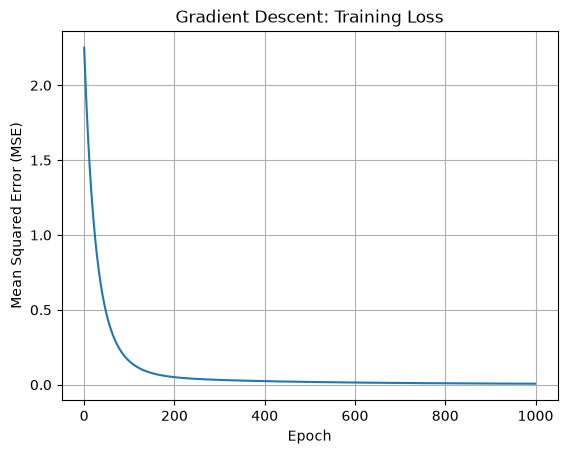

In [29]:

import matplotlib.pyplot as plt

plt.plot(loss_history)
plt.title("Gradient Descent: Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.grid(True)
plt.show()


In [30]:

import numpy as np
import matplotlib.pyplot as plt
import time

learning_rates = [0.0001, 0.01, 0.1]
epochs = 1000

lr_results = {}

for lr in learning_rates:
    # Start each experiment from the same initial values
    w = np.zeros(X_train.shape[1])
    b = 0.0
    losses = []
    start_time = time.perf_counter()

    for epoch in range(epochs):
        predictions = predict(X_train, w, b)
        mse = calculate_mse(y_train, predictions)

        # Stop if the model becomes numerically unstable
        if not np.isfinite(mse):
            break

        losses.append(mse)

        dw, db = calculate_gradients(
            X_train, y_train, predictions
        )

        w = w - lr * dw
        b = b - lr * db

    elapsed = time.perf_counter() - start_time

    lr_results[lr] = {
        "losses": losses,
        "weights": w,
        "bias": b,
        "time": elapsed
    }

    final_loss = losses[-1] if losses else float("inf")

    print(
        f"Learning rate: {lr} | "
        f"Epochs completed: {len(losses)} | "
        f"Final MSE: {final_loss:.6f} | "
        f"Time: {elapsed:.4f} seconds"
    )


Learning rate: 0.0001 | Epochs completed: 1000 | Final MSE: 1.579678 | Time: 0.4126 seconds
Learning rate: 0.01 | Epochs completed: 1000 | Final MSE: 0.006808 | Time: 0.3571 seconds
Learning rate: 0.1 | Epochs completed: 1000 | Final MSE: 0.000054 | Time: 0.3340 seconds


In [31]:

lr = 1.0

w = np.zeros(X_train.shape[1])
b = 0.0
diverging_losses = []

for epoch in range(1000):
    predictions = predict(X_train, w, b)
    mse = calculate_mse(y_train, predictions)

    if not np.isfinite(mse) or mse > 1e100:
        print("Divergence detected at epoch:", epoch)
        break

    diverging_losses.append(mse)

    dw, db = calculate_gradients(X_train, y_train, predictions)

    w = w - lr * dw
    b = b - lr * db

print("Last recorded MSE:", diverging_losses[-1])


Divergence detected at epoch: 304
Last recorded MSE: 5.048718571020775e+99


linear regression using NumPy, without gradient descent

In [32]:
import time
import numpy as np

# Start timing
start_time = time.perf_counter()

# Calculate the weights and bias directly
X_train_with_bias = np.c_[
    np.ones(X_train.shape[0]),
    X_train
]

closed_form_params = np.linalg.pinv(X_train_with_bias) @ y_train

# Separate the bias and weights
closed_form_bias = closed_form_params[0]
closed_form_weights = closed_form_params[1:]

# Measure execution time
closed_form_time = time.perf_counter() - start_time

# Make predictions
closed_form_predictions = predict(
    X_test,
    closed_form_weights,
    closed_form_bias
)

# Evaluate the model
closed_form_mae = np.mean(
    np.abs(y_test - closed_form_predictions)
)

closed_form_mse = calculate_mse(
    y_test,
    closed_form_predictions
)

print("Closed-form weights:", closed_form_weights)
print("Closed-form bias:", closed_form_bias)
print("Test MAE:", closed_form_mae)
print("Test MSE:", closed_form_mse)
print("Execution time:", closed_form_time, "seconds")

Closed-form weights: [0.99990766 0.99993113 1.00002004 0.99927727]
Closed-form bias: 0.000377555647854485
Test MAE: 0.002962183671706339
Test MSE: 2.740292338919488e-05
Execution time: 0.022073199972510338 seconds


In [33]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import time

# Start timing
start_time = time.perf_counter()

# Create and train the model
sklearn_model = LinearRegression()
sklearn_model.fit(X_train, y_train)

# Measure training time
sklearn_time = time.perf_counter() - start_time

# Make predictions
sklearn_predictions = sklearn_model.predict(X_test)

# Evaluate the model
sklearn_mae = mean_absolute_error(y_test, sklearn_predictions)
sklearn_mse = mean_squared_error(y_test, sklearn_predictions)

print("Weights:", sklearn_model.coef_)
print("Bias:", sklearn_model.intercept_)
print("Test MAE:", sklearn_mae)
print("Test MSE:", sklearn_mse)
print("Execution time:", sklearn_time, "seconds")


Weights: [0.99990766 0.99993113 1.00002004 0.99927727]
Bias: 0.0003775556478596842
Test MAE: 0.002962183671710288
Test MSE: 2.740292338919391e-05
Execution time: 0.01620559999719262 seconds


Comparison of Linear Regression Methods

I implemented linear regression from scratch using gradient descent, calculated the solution directly using NumPy's pseudoinverse, and trained a model using scikit-learn.

The closed-form and scikit-learn models achieved almost identical results, with a test MAE of approximately 0.00296 and a test MSE of approximately 0.0000274. Both performed better than my gradient descent model, which had a test MAE of 0.02860 and a test MSE of 0.00890 after 1,000 epochs.

The closed-form method and scikit-learn found nearly identical weights and bias. Scikit-learn was slightly faster in this run, although execution times can vary. Overall, gradient descent helped me understand how a model learns, while the other two methods reached a more accurate solution for this dataset.


Metric	(Gradient Descent)	     (NumPy)	       Scikit-learn
Test MAE	0.028603	        0.002962	       0.002962
Test MSE	0.008899	       0.000027            0.0000274
Execution time	          	   0.0221 s	           0.0162 s
Method	Iterative updates	Direct calculation	Built-in algorithm

In [34]:

# Make a copy so the original data stays unchanged
y_train_outlier = y_train.copy()

# Add an extreme outlier to one training target
outlier_index = np.argmax(y_train_outlier)
y_train_outlier[outlier_index] += 100

print("Original target:", y_train[outlier_index])
print("Target with outlier:", y_train_outlier[outlier_index])


Original target: 40.24
Target with outlier: 140.24


In [35]:

# 1. From-scratch gradient descent
outlier_weights = np.zeros(X_train.shape[1])
outlier_bias = 0.0
learning_rate = 0.01
epochs = 1000

for epoch in range(epochs):
    predictions = predict(X_train, outlier_weights, outlier_bias)
    dw, db = calculate_gradients(
        X_train, y_train_outlier, predictions
    )
    outlier_weights -= learning_rate * dw
    outlier_bias -= learning_rate * db

scratch_outlier_predictions = predict(
    X_test, outlier_weights, outlier_bias
)

# 2. Closed-form solution
X_train_bias = np.c_[np.ones(X_train.shape[0]), X_train]
outlier_params = np.linalg.pinv(X_train_bias) @ y_train_outlier

closed_outlier_bias = outlier_params[0]
closed_outlier_weights = outlier_params[1:]

closed_outlier_predictions = predict(
    X_test, closed_outlier_weights, closed_outlier_bias
)

# 3. Scikit-learn
sklearn_outlier = LinearRegression()
sklearn_outlier.fit(X_train, y_train_outlier)
sklearn_outlier_predictions = sklearn_outlier.predict(X_test)

# Evaluate all models on the original test targets
print("FROM-SCRATCH GRADIENT DESCENT")
print("MAE:", mean_absolute_error(y_test, scratch_outlier_predictions))
print("MSE:", mean_squared_error(y_test, scratch_outlier_predictions))

print("\nCLOSED-FORM NUMPY")
print("MAE:", mean_absolute_error(y_test, closed_outlier_predictions))
print("MSE:", mean_squared_error(y_test, closed_outlier_predictions))

print("\nSCIKIT-LEARN")
print("MAE:", mean_absolute_error(y_test, sklearn_outlier_predictions))
print("MSE:", mean_squared_error(y_test, sklearn_outlier_predictions))


FROM-SCRATCH GRADIENT DESCENT
MAE: 0.12568698178208346
MSE: 0.12257429043146897

CLOSED-FORM NUMPY
MAE: 0.12679311951080338
MSE: 0.11061033348811643

SCIKIT-LEARN
MAE: 0.1267931195108058
MSE: 0.11061033348812045


Model	          MAE before	MAE after	MSE before	MSE after
Gradient Descent	0.02860	     0.12569	0.008899	0.122574
Closed-form NumPy	0.002962	 0.12679	0.0000274	0.110610
Scikit-learn	    0.002962      0.12679	0.0000274	0.110610

Outlier Experiment Analysis

I introduced an artificial outlier by increasing one training target from 40.24 to 140.24. I then evaluated all three models using the original test dataset.

The outlier caused the test MAE and MSE to increase significantly for every model. For example, the closed-form model's MAE increased from approximately 0.00296 to 0.12679. This demonstrates that linear regression is sensitive to extreme values because they can influence the fitted weights and bias.

The closed-form NumPy and scikit-learn models produced almost identical results. Gradient descent produced slightly different errors because it uses iterative updates and was trained for a fixed number of epochs.

Metric	 Gradient Descent	Closed-form NumPy	Scikit-learn
Test MAE	0.028603 	        0.002962	      0.002962
Test MSE	0.008899	        0.0000274	       0.0000274
Executiontime (seconds)	0.2951	  0.0221	        0.0162
Main approach	Iterative updates	Direct calculation	Built-in linear regression
  Accuracy	         Good	         Excellent	   Excellent

Comparison of Linear Regression Methods

I compared three approaches to linear regression: gradient descent implemented from scratch, the closed-form solution using NumPy, and scikit-learn's LinearRegression.

Gradient descent took approximately 0.295 seconds and achieved a test MAE of 0.02860 and a test MSE of 0.00890. The closed-form method took approximately 0.022 seconds, while scikit-learn took approximately 0.016 seconds. Both achieved a test MAE of 0.00296 and a test MSE of 0.0000274.

The closed-form and scikit-learn models were more accurate on this dataset because they reached a solution closer to the underlying relationship between regional sales and global sales. Gradient descent helped me understand how weights and bias are updated iteratively. Scikit-learn was the fastest in my experiment and required the least code, making it convenient for practical applications.

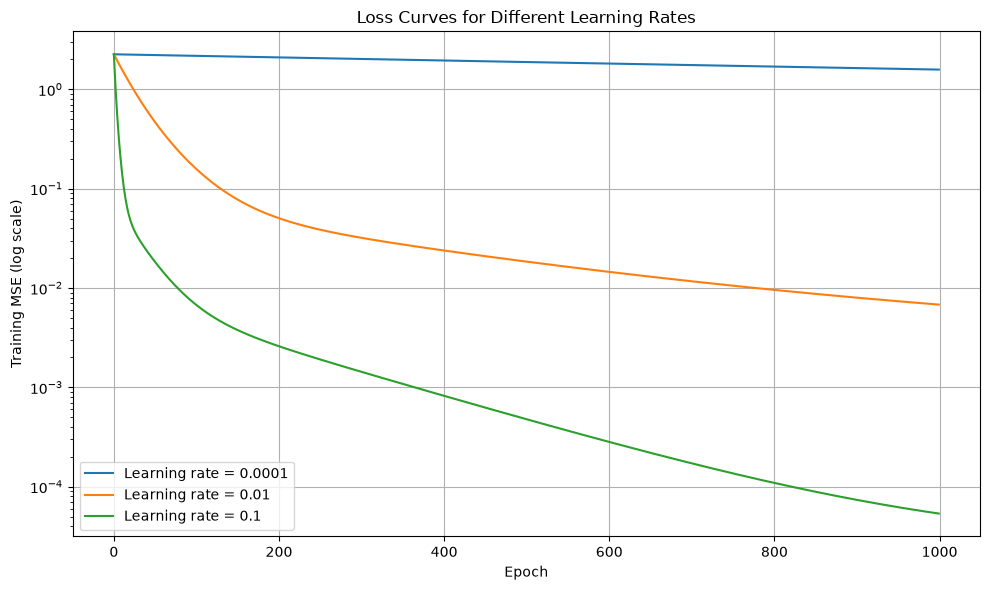

In [37]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for lr, result in lr_results.items():
    plt.plot(
        range(len(result["losses"])),
        result["losses"],
        label=f"Learning rate = {lr}"
    )

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training MSE (log scale)")
plt.title("Loss Curves for Different Learning Rates")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
